In [ ]:
from datasets import load_dataset

dataset = load_dataset("capa2000/binary-classifier-birdnet")
train_dataset = dataset["train"]
test_dataset = dataset["test"]

README.md:   0%|          | 0.00/724 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  105MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 27.5MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/80 [00:00<?, ? examples/s]

In [ ]:
import librosa
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

def get_features(obj):
    mfcc = librosa.feature.mfcc(y=obj["audio"]["array"], sr=obj["audio"]["sampling_rate"], n_mfcc=12)
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)])

X_train = np.array([get_features(obj) for obj in train_dataset])
y_train = np.array([0 if label == "Acropternis orthonyx" else 1 for label in train_dataset["nombreCientifico"]])
X_test = np.array([get_features(obj) for obj in test_dataset])
y_test = np.array([0 if label == "Acropternis orthonyx" else 1 for label in test_dataset["nombreCientifico"]])

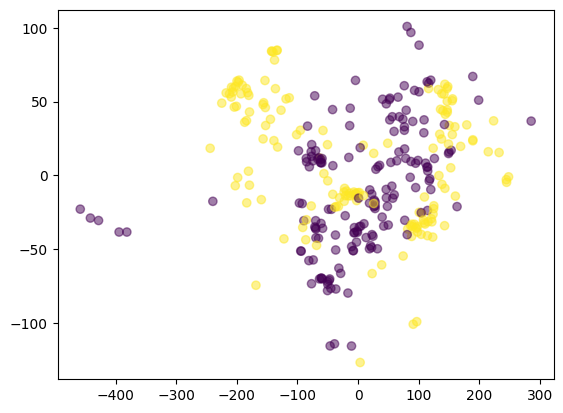

In [ ]:
x2d = PCA(2).fit_transform(X_train)
plt.scatter(x2d[:, 0], x2d[:, 1], c=y_train, alpha=0.5)
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
models = [make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)), RandomForestClassifier(n_estimators=500), make_pipeline(StandardScaler(), SVC())]
names = ["Logistic Regression", "Random Forest", "SVM"]
for name, model in zip(names, models):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"Model: {name} | Accuracy: {accuracy_score(pred, y_test)}")

Model: Logistic Regression | Accuracy: 0.95
Model: Random Forest | Accuracy: 0.975
Model: SVM | Accuracy: 0.95


In [ ]:
from transformers import ClapModel, ClapProcessor
from tqdm import tqdm
import torch
model_clap = ClapModel.from_pretrained("laion/clap-htsat-fused")
processor = ClapProcessor.from_pretrained("laion/clap-htsat-fused")
def get_new_feature(obj):
    audio = librosa.resample(obj["audio"]["array"], orig_sr=obj["audio"]["sampling_rate"], target_sr=48000)
    with torch.no_grad():
        return model_clap.get_audio_features(**processor(audio=audio, sampling_rate=48000, return_tensors="pt")).pooler_output.squeeze(0).cpu().numpy()
X_train_Clap = [get_new_feature(obj) for obj in tqdm(train_dataset)]
X_test_Clap = [get_new_feature(obj) for obj in tqdm(test_dataset)]

Loading weights:   0%|          | 0/477 [00:00<?, ?it/s]

100%|██████████| 80/80 [00:43<00:00,  1.86it/s]


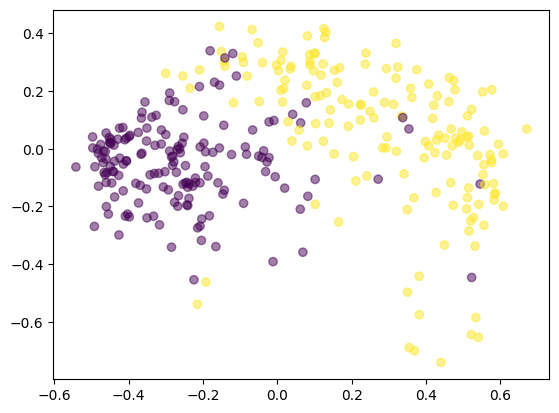

In [ ]:
x2d_Clap = PCA(2).fit_transform(X_train_Clap)
plt.scatter(x2d_Clap[:, 0], x2d_Clap[:, 1], c=y_train, alpha=0.5)
plt.show()

In [ ]:
models = [make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)), RandomForestClassifier(n_estimators=500), make_pipeline(StandardScaler(), SVC())]
names = ["Logistic Regression", "Random Forest", "SVM"]
for name, model in zip(names, models):
    model.fit(X_train_Clap, y_train)
    pred = model.predict(X_test_Clap)
    print(f"Model: {name} | Accuracy: {accuracy_score(pred, y_test)}")

Model: Logistic Regression | Accuracy: 0.975
Model: Random Forest | Accuracy: 0.95
Model: SVM | Accuracy: 0.9875


In [ ]:
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
X_train_tensor = torch.tensor(X_train_Clap, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_Clap, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=32, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_tensor, y_test_tensor), batch_size=32, shuffle=False)

/tmp/ipykernel_649/3930403251.py:3: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  X_train_tensor = torch.tensor(X_train_Clap, dtype=torch.float32)


In [ ]:
print(X_train_Clap[0].shape)

(512,)


In [ ]:
fc = nn.Linear(512, 2)
risk = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(fc.parameters(), lr=1e-3)
for epoch in range(60):
    fc.train()
    for x, y in train_loader:
        optimizer.zero_grad()
        logits = fc(x)
        loss = risk(logits, y)
        loss.backward()
        optimizer.step()
    if (epoch + 1) % 5 == 0:
        print(f"Epoch: {epoch + 1} | Loss: {loss.item()}")
all_preds = []
fc.eval()
with torch.no_grad():
    for x, y in test_loader:
        preds = torch.argmax(fc(x), dim=1)
        all_preds.extend(preds.cpu().numpy())
print(f"Accuracy: {accuracy_score(all_preds, y_test)}")

Epoch: 5 | Loss: 0.5217992067337036
Epoch: 10 | Loss: 0.4675181210041046
Epoch: 15 | Loss: 0.36199215054512024
Epoch: 20 | Loss: 0.3203897476196289
Epoch: 25 | Loss: 0.21220773458480835
Epoch: 30 | Loss: 0.3473440408706665
Epoch: 35 | Loss: 0.27450665831565857
Epoch: 40 | Loss: 0.29763397574424744
Epoch: 45 | Loss: 0.15753839910030365
Epoch: 50 | Loss: 0.22430402040481567
Epoch: 55 | Loss: 0.27701640129089355
Epoch: 60 | Loss: 0.1796913892030716
Accuracy: 0.9375


In [ ]:
for param in model_clap.parameters():
    param.requires_grad = True
optimizer = torch.optim.Adam(list(model_clap.parameters()) + list(fc.parameters()), lr=1e-4)
risk = nn.CrossEntropyLoss()
for epoch in range(5):
    fc.train()
    model_clap.eval()
    total_loss = 0
    for x, y in tqdm(zip(train_dataset, y_train), total=len(train_dataset)):
        optimizer.zero_grad()
        audio = librosa.resample(x["audio"]["array"], orig_sr=x["audio"]["sampling_rate"], target_sr=48000)
        features = model_clap.get_audio_features(**processor(audio=audio, sampling_rate=48000, return_tensors="pt")).pooler_output.squeeze(0)
        logits = fc(features).unsqueeze(0)
        loss = risk(logits, torch.tensor([y]))
        total_loss += loss.item()
        loss.backward()
        optimizer.step()
    print(f"Epoch: {epoch + 1} | Loss: {total_loss / len(train_dataset)}")

100%|██████████| 320/320 [08:48<00:00,  1.65s/it]


Epoch: 1 | Loss: 0.7224320338560574


100%|██████████| 320/320 [04:43<00:00,  1.13it/s]


Epoch: 2 | Loss: 0.7108378472272306


100%|██████████| 320/320 [04:35<00:00,  1.16it/s]


Epoch: 3 | Loss: 0.6971203903085552


100%|██████████| 320/320 [04:31<00:00,  1.18it/s]


Epoch: 4 | Loss: 0.6384096861147555


100%|██████████| 320/320 [04:37<00:00,  1.15it/s]

Epoch: 5 | Loss: 0.7045508529059589


In [ ]:
X_train_Clap_tuned = [get_new_feature(obj) for obj in tqdm(train_dataset)]
X_test_Clap_tuned = [get_new_feature(obj) for obj in tqdm(test_dataset)]

100%|██████████| 80/80 [00:37<00:00,  2.13it/s]


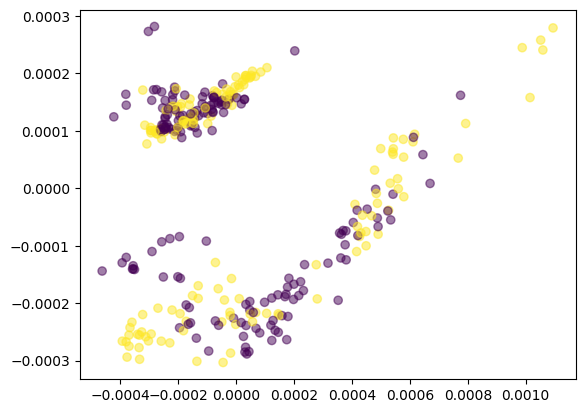

In [ ]:
x2d_Clap_tuned = PCA(2).fit_transform(X_train_Clap_tuned)
plt.scatter(x2d_Clap_tuned[:, 0], x2d_Clap_tuned[:, 1], c=y_train, alpha=0.5)
plt.show()

In [ ]:
for name, model in zip(names, models):
    model.fit(X_train_Clap_tuned, y_train)
    pred = model.predict(X_test_Clap_tuned)
    print(f"Model: {name} | Accuracy: {accuracy_score(pred, y_test)}")

Model: Logistic Regression | Accuracy: 0.9375
Model: Random Forest | Accuracy: 0.925
Model: SVM | Accuracy: 0.9125


In [ ]:
from sklearn.metrics import pairwise_distances
X_all = np.vstack([X_train_Clap, X_test_Clap])
all_data = list(train_dataset) + list(test_dataset)
d = pairwise_distances(X_all)
np.fill_diagonal(d, np.inf)
distmin = np.inf
distmax = -np.inf
n = d.shape[0]
for i in range(n):
    for j in range(i + 1, n):
        if d[i][j] < distmin:
            distmin = d[i][j]
            ans_min = (i, j)
        if d[i][j] > distmax:
            distmax = d[i][j]
            ans_max = (i, j)
ans_min, ans_max

((138, 378), (183, 306))

In [ ]:
def show_spectrogram(obj):
    stft = librosa.stft(obj["audio"]["array"])
    stft_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)
    plt.figure(figsize=(10, 5))
    librosa.display.specshow(stft_db, sr=obj["audio"]["sampling_rate"], y_axis="hz", x_axis="time")
    plt.tight_layout()
    plt.show()

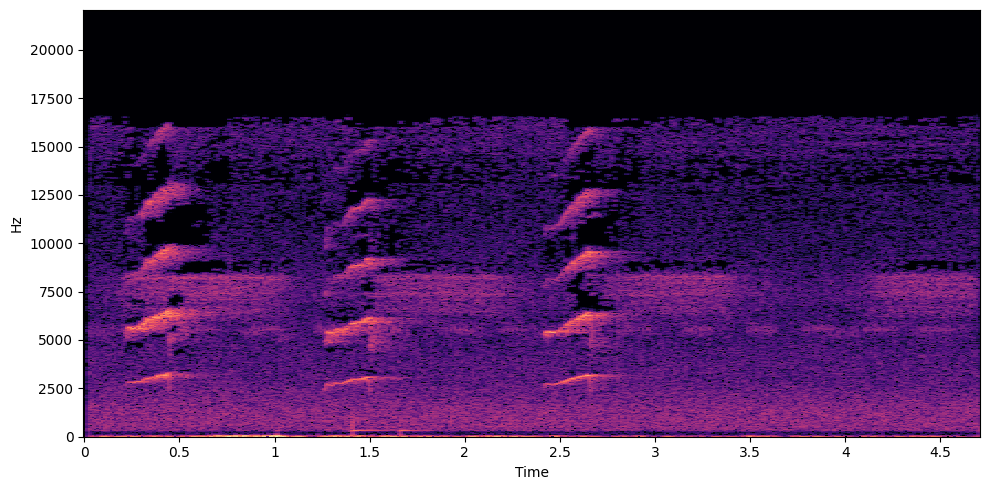

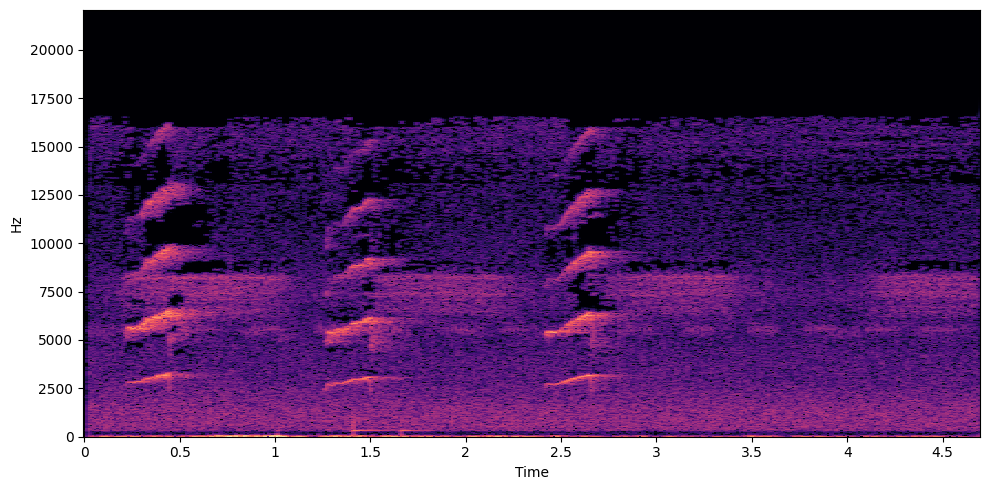

{'archivo': '20160102T1100_Accipiter_striatus_[-22.435,-42.9326]_0.00s_5s.wav', 'nombreCientifico': 'Accipiter striatus', 'fmin': 1961.7833251953125, 'fmax': 4815.28662109375, 'duration_s': 5, 'audio': <datasets.features._torchcodec.AudioDecoder object at 0x7e5fe3f83000>}
{'archivo': '20160102T1100_Accipiter_striatus_[-22.435,-42.9326]_-0.31s_5s.wav', 'nombreCientifico': 'Accipiter striatus', 'fmin': 1961.7833251953125, 'fmax': 4815.28662109375, 'duration_s': 5, 'audio': <datasets.features._torchcodec.AudioDecoder object at 0x7e5fe3fa6c10>}


In [ ]:
x1, x2 = ans_min
show_spectrogram(all_data[x1])
show_spectrogram(all_data[x2])
print(all_data[x1], all_data[x2], sep='\n')

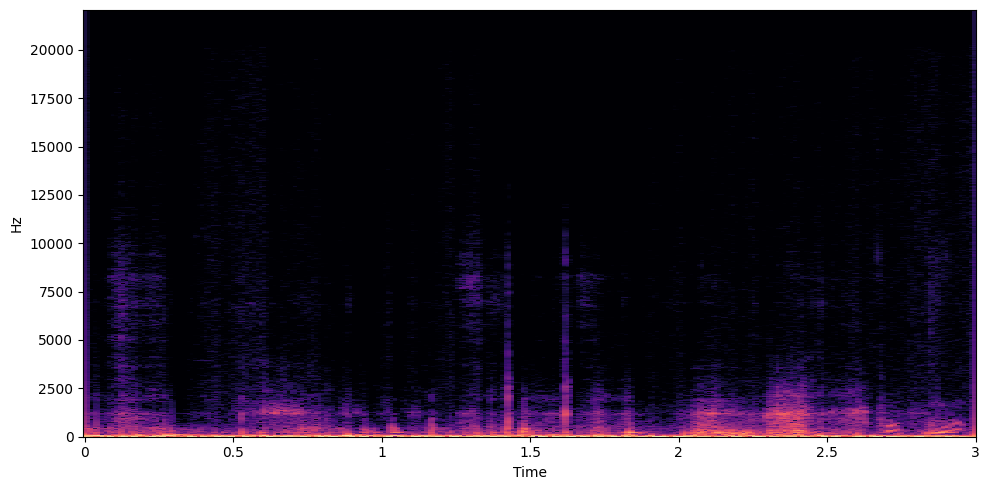

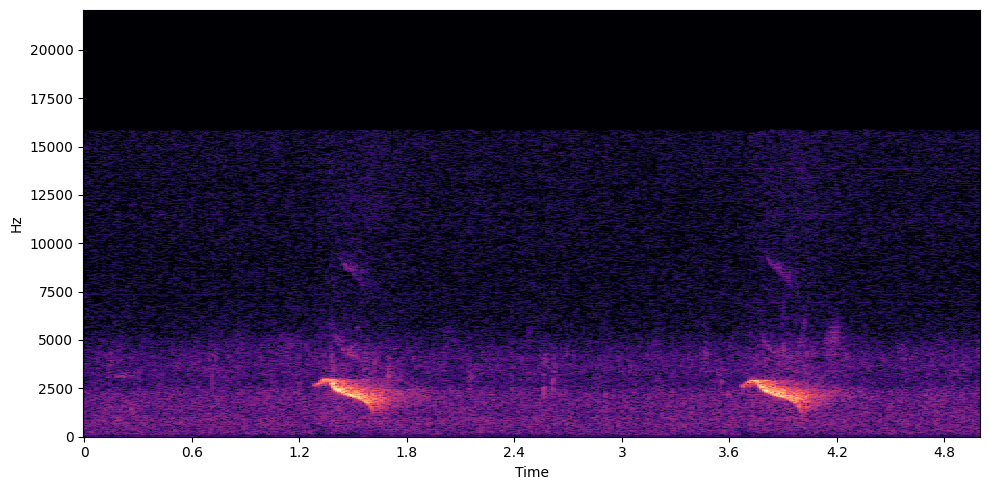

{'archivo': '20240918T1030_Accipiter_striatus_[45.6703,-86.9671]_29.00s_3s.wav', 'nombreCientifico': 'Accipiter striatus', 'fmin': 1961.7833251953125, 'fmax': 4815.28662109375, 'duration_s': 3, 'audio': <datasets.features._torchcodec.AudioDecoder object at 0x7e5fe3fbeba0>}
{'archivo': '20160413T1430_Acropternis_orthonyx_[5.005,-75.327]_24.45s_5s.wav', 'nombreCientifico': 'Acropternis orthonyx', 'fmin': 2050.955322265625, 'fmax': 3210.191162109375, 'duration_s': 5, 'audio': <datasets.features._torchcodec.AudioDecoder object at 0x7e5fe3fa8d00>}


In [ ]:
x1, x2 = ans_max
show_spectrogram(all_data[x1])
show_spectrogram(all_data[x2])
print(all_data[x1], all_data[x2], sep='\n')